In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import NullFormatter
from IPython.display import display
from scipy.integrate import quad_vec

from shared.common import (jump_prob, load_config, normal_cell_mass, normal_density,
                           plot_setup, save_figure, split_point)

In [2]:
config = load_config()['benchmark']
out = Path('../output')
U = config['wind_m_s']
K = np.array(config['diffusivity_m2_s'])
H, Q = config['source_height_m'], config['release_g_s']
T, slice_t = config['duration_s'], config['plume_slice_s']
slice_x, slice_z = config['slice_x_m'], config['slice_z_m']
puff_times = config['puff_times_s']
plot_setup()

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [3]:
def move_axis(mass, prob, reflect=False):
    minus, stay, plus = prob
    result = stay * mass
    result[:-1] += minus * mass[1:]
    result[1:] += plus * mass[:-1]
    if reflect:
        result[0] += minus * mass[0]
    return result


def puff_density(age, x, y, z):
    # image source gives zero normal flux at z = 0
    if age <= 0:
        return np.zeros_like(y, dtype=float)
    sx, sy, sz = np.sqrt(2*K*age)
    vertical = normal_density(z, H, sz) + normal_density(z, -H, sz)
    return normal_density(x, U*age, sx) * normal_density(y, 0, sy) * vertical


def steady_diffusive(x, y, z):
    radius = np.sqrt((x*x/K[0] + y*y/K[1]) + (np.array([z-H, z+H])[:, None]**2 / K[2]))
    decay = U / (2*np.sqrt(K[0]))
    return Q * np.sum(np.exp(U*x/(2*K[0]) - decay*radius) / radius, axis=0) / (4*np.pi*np.sqrt(np.prod(K)))


def steady_paraxial(x, y, z):
    sy, sz = np.sqrt(2*K[1:]*x/U)
    return (Q/U) * normal_density(y, 0, sy) * (normal_density(z, H, sz) + normal_density(z, -H, sz))

In [4]:
scores, arrival_rows, slice_rows = [], [], []
for h in config['spacing_m']:
    n_per_s = int(np.ceil(max(K)/(0.15*h*h)))
    dt = 1/n_per_s
    centers = [np.arange(-20, 112 + h/2, h), np.arange(-36, 36 + h/2, h), np.arange(h/2, 38, h)]
    edges = [np.r_[axis - h/2, axis[-1] + h/2] for axis in centers]
    probabilities = jump_prob([U, 0, 0], K, h, dt)
    assert np.all(probabilities >= 0) and np.allclose(probabilities.sum(axis=1), 1)
    variances = (probabilities[:, 0] + probabilities[:, 2]) - (probabilities[:, 2] - probabilities[:, 0])**2
    assert np.allclose(h*h*variances / (2*dt), K)
    # homogeneous 27-point rule factors exactly into the three 1D operators
    axes = [np.zeros(len(axis)) for axis in centers]
    for axis, coords, point in zip(axes, centers, [0, 0, H]):
        for i, weight in split_point(coords, point):
            axis[i] += weight
    y = centers[1]
    profile = np.zeros_like(y)
    for step in range(1, T*n_per_s + 1):
        axes = [move_axis(axis, prob, reflect=i == 2)
                for i, (axis, prob) in enumerate(zip(axes, probabilities))]
        age = step/n_per_s
        at_receptor = (np.interp(slice_x, centers[0], axes[0])
                       * np.interp(slice_z, centers[2], axes[2])) * axes[1] / h**3
        # trapezoidal convolution with the impulse history
        continuous = profile + 0.5*Q*dt*at_receptor
        profile += Q*dt*at_receptor
        if step % n_per_s == 0:
            arrival_rows.append((h, age, continuous[len(y)//2]))
        if age == slice_t:
            ref = Q*quad_vec(lambda a: puff_density(a, slice_x, y, slice_z), 0, age)[0]
            slice_rows.extend(zip(np.full(len(y), h), y, continuous, ref))
            scores.append({'test': 'finite_release_profile', 'spacing_m': h, 'time_s': age,
                           'rel_l1': np.abs(continuous-ref).sum()/ref.sum()})
        if age in puff_times:
            sx, sy, sz = np.sqrt(2*K*age)
            mx = normal_cell_mass(edges[0], U*age, sx)
            my = normal_cell_mass(edges[1], 0, sy)
            mz = normal_cell_mass(edges[2], H, sz) + normal_cell_mass(edges[2], -H, sz)
            actual = np.einsum('i,j,k->ijk', *axes)
            expected = np.einsum('i,j,k->ijk', mx, my, mz)
            scores.append({'test': 'pulse_cell_mass', 'spacing_m': h, 'time_s': age,
                           'rel_l1': np.abs(actual-expected).sum()/expected.sum(),
                           'puff_mass': actual.sum(), 'reference_mass': expected.sum(),
                           'mean_x_m': np.dot(centers[0], axes[0])/axes[0].sum(),
                           'mean_x_expected_m': U*age})
    steady = steady_diffusive(slice_x, y, slice_z)
    scores.append({'test': 'late_release_vs_exact_steady', 'spacing_m': h, 'time_s': T,
                   'rel_l1': np.abs(continuous-steady).sum()/steady.sum()})

In [5]:
benchmark = pd.DataFrame(scores)
arrival = pd.DataFrame(arrival_rows, columns=['spacing_m', 'time_s', 'ca_g_m3'])
slices = pd.DataFrame(slice_rows, columns=['spacing_m', 'y_m', 'ca_g_m3', 'analytic_g_m3'])
arrival_ref = pd.DataFrame({'time_s': sorted(arrival['time_s'].unique())})
arrival_ref['analytic_g_m3'] = [Q*quad_vec(lambda a: puff_density(a, slice_x, np.array([0]), slice_z), 0, t)[0][0]
                                for t in arrival_ref['time_s']]
arrival = arrival.merge(arrival_ref, on='time_s', validate='many_to_one')
wide_y = np.linspace(-95, 95, 1001)
paraxial = []
for x in [6, 12, 24, 48, 72, 96]:
    exact = steady_diffusive(x, wide_y, slice_z)
    approximation = steady_paraxial(x, wide_y, slice_z)
    paraxial.append({'x_m': x, 'peclet_x': U*x/K[0],
                     'rel_l1_classical_vs_exact': np.abs(approximation-exact).sum()/exact.sum()})
paraxial = pd.DataFrame(paraxial)

In [6]:
pivot = benchmark.pivot(index=['test', 'time_s'], columns='spacing_m', values='rel_l1')
assert (pivot[min(config['spacing_m'])] < pivot[max(config['spacing_m'])]).all()
assert benchmark.query("test == 'pulse_cell_mass'")['puff_mass'].min() > 0.999
benchmark.to_csv(out / 'benchmark_scores.csv', index=False)
arrival.to_csv(out / 'arrival.csv', index=False)
slices.to_csv(out / 'crosswind_slices.csv', index=False)
paraxial.to_csv(out / 'paraxial_error.csv', index=False)
display(benchmark.round(5))
display(paraxial.round(5))

,test,spacing_m,time_s,rel_l1,puff_mass,reference_mass,mean_x_m,mean_x_expected_m
0,pulse_cell_mass,2.0,5.0,0.08392,1.0,1.0,6.0,6.0
1,pulse_cell_mass,2.0,10.0,0.03034,1.0,1.0,12.0,12.0
2,pulse_cell_mass,2.0,20.0,0.01434,1.0,1.0,24.0,24.0
3,finite_release_profile,2.0,30.0,0.00758,NaN,NaN,NaN,NaN
4,late_release_vs_exact_steady,2.0,60.0,0.00714,NaN,NaN,NaN,NaN
5,pulse_cell_mass,1.0,5.0,0.01225,1.0,1.0,6.0,6.0
6,pulse_cell_mass,1.0,10.0,0.00629,1.0,1.0,12.0,12.0
7,pulse_cell_mass,1.0,20.0,0.00338,1.0,1.0,24.0,24.0
8,finite_release_profile,1.0,30.0,0.00255,NaN,NaN,NaN,NaN
9,late_release_vs_exact_steady,1.0,60.0,0.00256,NaN,NaN,NaN,NaN


,x_m,peclet_x,rel_l1_classical_vs_exact
0,6,6.0,0.09907
1,12,12.0,0.05925
2,24,24.0,0.03007
3,48,48.0,0.01391
4,72,72.0,0.00884
5,96,96.0,0.00644


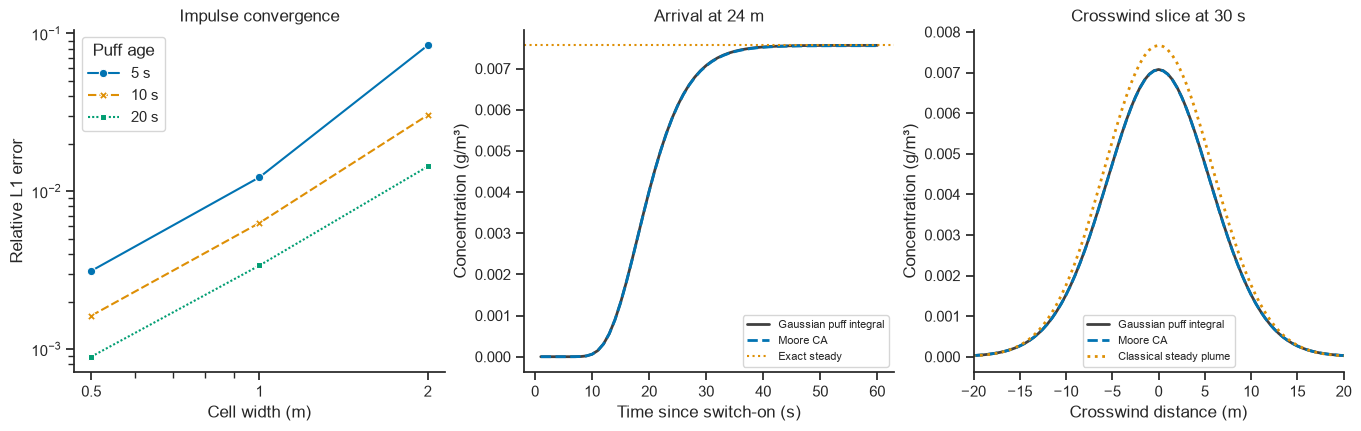

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), layout='constrained')
puff = benchmark.query("test == 'pulse_cell_mass'").copy()
puff['Puff age'] = puff['time_s'].map(lambda t: f'{t:g} s')
sns.lineplot(data=puff, x='spacing_m', y='rel_l1', hue='Puff age', style='Puff age',
             markers=True, dashes=True, ax=axes[0])
axes[0].set(xscale='log', yscale='log', xlabel='Cell width (m)', ylabel='Relative L1 error', title='Impulse convergence')
spacing = sorted(config['spacing_m'])
axes[0].set_xticks(spacing, labels=[f'{h:g}' for h in spacing])
axes[0].xaxis.set_minor_formatter(NullFormatter())
fine = min(config['spacing_m'])
trace = arrival.query('spacing_m == @fine')
axes[1].plot(trace['time_s'], trace['analytic_g_m3'], color='0.25', lw=2, label='Gaussian puff integral')
axes[1].plot(trace['time_s'], trace['ca_g_m3'], '--', color='C0', lw=2, label='Moore CA')
axes[1].axhline(steady_diffusive(slice_x, np.array([0]), slice_z)[0], ls=':', color='C1', label='Exact steady')
axes[1].set(xlabel='Time since switch-on (s)', ylabel='Concentration (g/m³)', title=f'Arrival at {slice_x:g} m')
axes[1].legend(fontsize=8)
trace = slices.query('spacing_m == @fine')
axes[2].plot(trace['y_m'], trace['analytic_g_m3'], color='0.25', lw=2, label='Gaussian puff integral')
axes[2].plot(trace['y_m'], trace['ca_g_m3'], '--', color='C0', lw=2, label='Moore CA')
axes[2].plot(trace['y_m'], steady_paraxial(slice_x, trace['y_m'].to_numpy(), slice_z),
             ':', color='C1', lw=2, label='Classical steady plume')
axes[2].set(xlabel='Crosswind distance (m)', ylabel='Concentration (g/m³)',
            title=f'Crosswind slice at {slice_t:g} s', xlim=(-20, 20))
axes[2].legend(fontsize=8)
sns.despine(fig=fig)
save_figure(fig, out, 'gaussian_benchmark')
display(fig)
plt.close(fig)